# 07 · Age, mileage and the late-age price rebound

## tl;dr

In the $500–$150,000 cohort, the geometric mean asking-price gap between listings aged 40+ and 20–24 years fell from **+141%** before adjustment to **+26.5%** (95% interval **+15.0% to +39.1%**) among listings with comparable make, vehicle type and mileage bands. That comparison covers 15 shared strata with 589 listings aged 20–24 and 1,104 aged 40+. Nonlinear splines reduced dollar MAE in all three April validation windows. Adding an age-by-mileage interaction helped by much less than adding nonlinear terms. A quantile model distinguished the price bands, with 47.2% observed coverage for a nominal middle-50% range in the latest April window.

## Context & Methods

[Research question 2](../docs/proposal.md#research-questions) asks how vehicle age and odometer readings relate to asking price. The first pass found an older-vehicle rebound in grouped medians and a negative average age slope in [notebook 05](05_adjusted_associations_and_prediction.ipynb). A nonlinear model and comparisons within shared vehicle segments help clarify why both patterns can appear in the same snapshot.

- **Describe:** median and middle half of prices by age and mileage bands.
- **Compare like with like:** compare ages 40+ and 20–24 within shared make, vehicle type and mileage strata. Pool log-price contrasts using overlap weights. Compare with type-and-mileage strata and repeat with positive mileage only and with all positive prices.
- **Model shape:** compare ridge models with linear terms, additive cubic splines and cubic marginal splines plus a lower-rank age-by-mileage spline. Keep the price target, predictors and validation listings fixed. A separate unpenalized fit with the same interaction basis provides pointwise intervals for contrasts.
- **Model spread:** fit three quantile boosting models. On a later April block, check whether observed prices fall below each fitted quantile at approximately its nominal rate.

### Key assumptions

Age is posting year minus model year. A given vehicle contributes a listing snapshot, so fitted age differences compare vehicles at different ages. Mileage is in miles. Zero mileage is retained as reported and omitted in a sensitivity comparison. Adjusted regressions control for make, type, condition, fuel, title status, transmission, drivetrain and state. Categories describe the recorded listing attributes. Results depend on available measurements, the price band, the covariates and the dates in the Kaggle snapshot.

In [1]:
from pathlib import Path
import json
import sys
import os

# Bound native numerical threads so this notebook can run with the other questions.
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = "2"

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
if not (root / "src" / "research_data.py").exists():
    raise FileNotFoundError("Open this notebook from the project root or the notebooks directory.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd
from IPython.display import display

from src.research_data import load_research_data
from src.q2_age_mileage import (
    MIN_SUPPORT, MODEL_NAMES, adjusted_difference, binned_summary, eligible_rows,
    fit_adjusted, quantile_diagnostic, rebound_audit, rolling_spline_scores, support_counts,
)

output_dir = root / "outputs" / "q2"
output_dir.mkdir(parents=True, exist_ok=True)

INK, MUTED, LINE = "#183447", "#516678", "#d6e1e9"
BLUE, TEAL, ORANGE = "#255b86", "#087c7e", "#b45f37"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "axes.titleweight": "bold",
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": LINE,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": LINE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.dpi": 110, "savefig.dpi": 220,
})
usd_tick = FuncFormatter(lambda value, _: f"${value/1_000:g}k" if value else "$0")
miles_tick = FuncFormatter(lambda value, _: f"{value/1_000:g}k" if value else "0")

def figure_notes(fig, title, subtitle, footer):
    fig.text(.07, .96, title, fontsize=18, fontweight="bold", va="top")
    fig.text(.07, .89, subtitle, fontsize=10, color=MUTED, va="top")
    fig.text(.07, .03, footer, fontsize=9, color=MUTED, va="bottom", linespacing=1.45)

def show_figure(fig, name):
    fig.savefig(output_dir / f"{name}.svg", bbox_inches="tight", pad_inches=.17)
    fig.savefig(output_dir / f"{name}.png", dpi=180, bbox_inches="tight", pad_inches=.17)
    plt.show()
    plt.close(fig)


## Data

Source: [Austin Reese, Craigslist Cars & Trucks Data, Kaggle version 10](https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data/versions/10). The shared loader uses the [project data instructions](../DATA.md) and the positive-price cleaning rules from [notebook 02](02_clean_and_derive.ipynb). The observed dates run from April to early May 2021. The exploratory and matched summaries use the snapshot, while model comparison and curve fitting use April. The May 1–4 window is a previously evaluated benchmark in notebook 05.

In [2]:
data = load_research_data(root)
positive = eligible_rows(data)
primary = positive.loc[positive.price_band].copy()
april = primary.loc[primary.posting_day.lt("2021-05-01")]
audit = pd.Series({
    "Positive asking prices after shared cleaning": len(data),
    "Complete age and mileage between 0 and 1 million": len(positive),
    "Complete age and mileage, price between $500 and $150,000": len(primary),
    "Primary cohort posted before May 1": len(april),
    "Zero mileage in the primary cohort": int(primary.odometer.eq(0).sum()),
}, name="Listings")
display(audit.to_frame().style.format("{:,}"))


,Listings
Positive asking prices after shared cleaning,"393,985"
Complete age and mileage between 0 and 1 million,"390,018"
"Complete age and mileage, price between $500 and $150,000","380,892"
Primary cohort posted before May 1,"283,517"
Zero mileage in the primary cohort,"1,061"


## Results

### 1. Raw price patterns

The two panels show the same complete-age-and-mileage, positive-price listings. The bar strips report the counts for each displayed bin. Bins are categorical on the horizontal axis, including the open-ended age group.

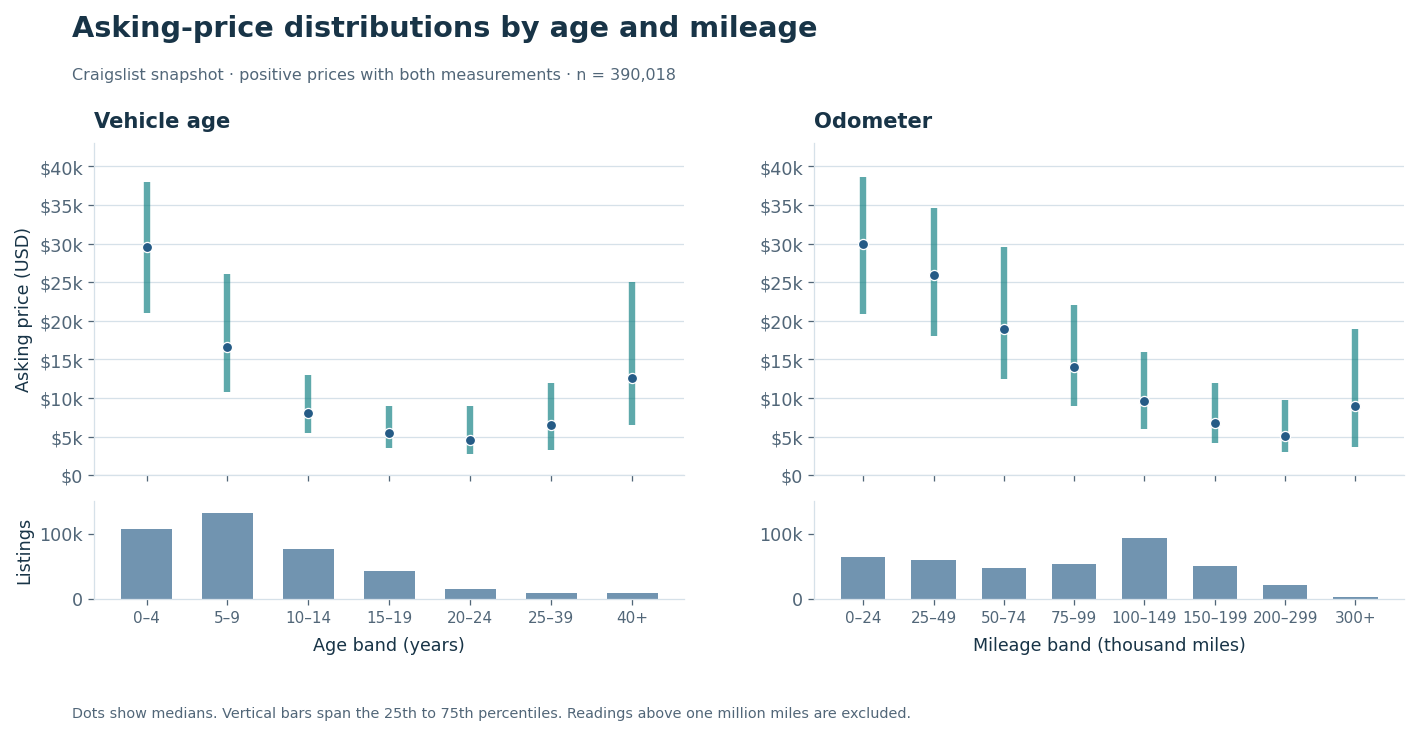

,n,p25,median,p75
vehicle_age,,,,
0–4,"107,292","20,990","29,595","37,998"
20–24,"14,368","2,800","4,500","8,977"
40+,"8,557","6,445","12,571","25,000"


In [3]:
age_labels = ["0–4", "5–9", "10–14", "15–19", "20–24", "25–39", "40+"]
miles_labels = ["0–24", "25–49", "50–74", "75–99", "100–149", "150–199", "200–299", "300+"]
age_stats = binned_summary(positive, "vehicle_age", [0, 5, 10, 15, 20, 25, 40, 200], age_labels)
mile_stats = binned_summary(positive, "odometer",
                            [0, 25_000, 50_000, 75_000, 100_000, 150_000, 200_000,
                             300_000, 1_000_001], miles_labels)
assert age_stats.n.sum() == mile_stats.n.sum() == len(positive)

fig, axes = plt.subplots(2, 2, figsize=(12.8, 6.6), sharex="col",
                         gridspec_kw={"height_ratios": [3.4, 1], "hspace": .12})
fig.subplots_adjust(left=.085, right=.975, bottom=.19, top=.79, wspace=.22)
for column, (values, title, xlabel) in enumerate([
    (age_stats, "Vehicle age", "Age band (years)"),
    (mile_stats, "Odometer", "Mileage band (thousand miles)"),
]):
    x = np.arange(len(values))
    ax, counts = axes[:, column]
    ax.set_title(title, loc="left", pad=10)
    ax.vlines(x, values.p25, values.p75, color=TEAL, alpha=.65, lw=4)
    ax.scatter(x, values["median"], color=BLUE, s=40, edgecolor="white", linewidth=.8, zorder=3)
    ax.yaxis.set_major_formatter(usd_tick)
    ax.set_ylim(0, 43_000)
    ax.grid(axis="y")
    counts.bar(x, values.n, width=.63, color=BLUE, alpha=.65)
    counts.set_ylim(0, 150_000)
    counts.set_yticks([0, 100_000], ["0", "100k"])
    counts.set_xticks(x, values.index, fontsize=9.5)
    counts.set_xlabel(xlabel, labelpad=7)
axes[0, 0].set_ylabel("Asking price (USD)")
axes[1, 0].set_ylabel("Listings")
figure_notes(fig, "Asking-price distributions by age and mileage",
             f"Craigslist snapshot · positive prices with both measurements · n = {len(positive):,}",
             "Dots show medians. Vertical bars span the 25th to 75th percentiles. Readings above one million miles are excluded.")
show_figure(fig, "01_raw_age_mileage")
display(age_stats.loc[["0–4", "20–24", "40+"]].style.format("{:,.0f}"))


### 2. Is the rebound driven by the mix of vehicles?

For each shared stratum, take the difference in mean log price between ages 40+ and 20–24. Weight the stratum by the product of the two group counts divided by their sum, then normalize weights to total one. This gives more weight to cells where both age groups are represented. Detailed matches require at least 20 listings in each age group within the same make, type and mileage band. Intervals use state-clustered influence scores and hold the overlap strata and weights fixed.

,Gap (%),95% low (%),95% high (%),Strata,"Age 20–24, n","Age 40+, n"
comparison,,,,,,
Raw · price band,+140.6,+122.2,+160.5,1,"14,108","8,334"
Same type + mileage,+37.2,+27.3,+47.9,23,"5,457","4,384"
Same make + type + mileage,+26.5,+15.0,+39.1,15,589,"1,104"
Detailed · positive mileage,+26.3,+14.9,+38.8,15,589,"1,096"
Detailed · all positive prices,+20.6,+0.5,+44.8,16,618,"1,191"


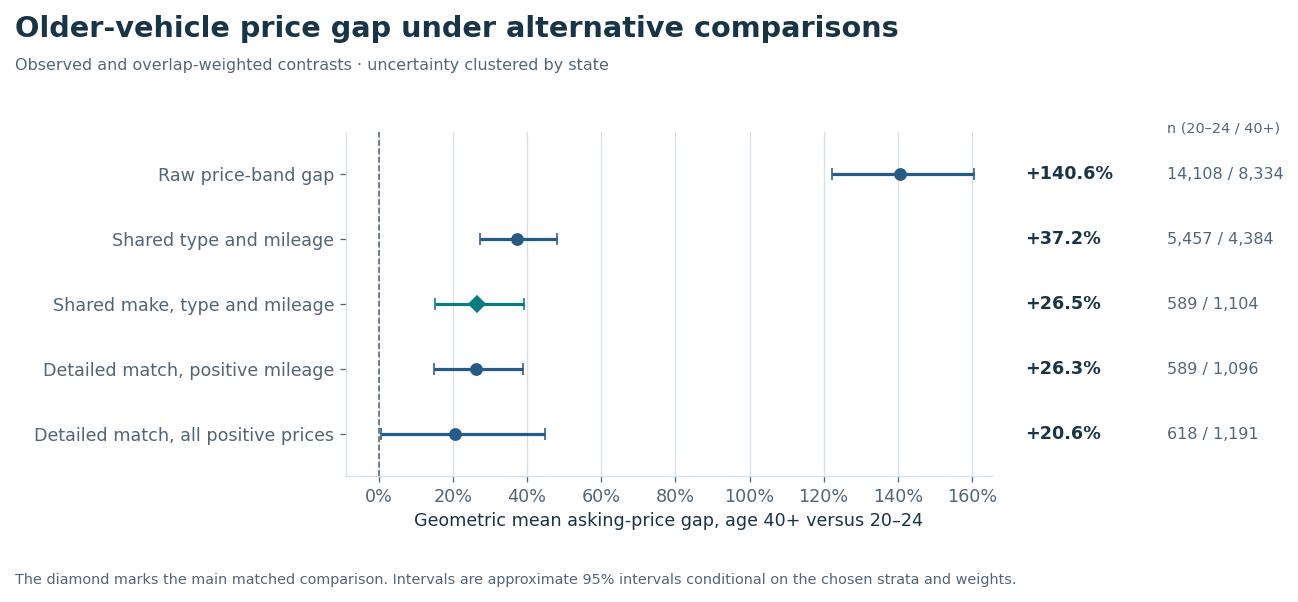

In [4]:
rebound = rebound_audit(primary, positive)
display(rebound.rename(columns={
    "estimate": "Gap (%)", "lower": "95% low (%)", "upper": "95% high (%)",
    "strata": "Strata", "n_20_24": "Age 20–24, n", "n_40_plus": "Age 40+, n",
}).style.format({
    "Gap (%)": "{:+.1f}", "95% low (%)": "{:+.1f}", "95% high (%)": "{:+.1f}",
    "Strata": "{:,}", "Age 20–24, n": "{:,}", "Age 40+, n": "{:,}",
}))

fig, ax = plt.subplots(figsize=(12.5, 5.35))
fig.subplots_adjust(left=.30, right=.75, bottom=.21, top=.77)
y = np.arange(len(rebound))[::-1]
labels = ["Raw price-band gap", "Shared type and mileage",
          "Shared make, type and mileage", "Detailed match, positive mileage",
          "Detailed match, all positive prices"]
for position, (_, row), index in zip(y, rebound.iterrows(), range(len(y))):
    ax.errorbar(row.estimate, position,
                xerr=[[row.estimate-row.lower], [row.upper-row.estimate]],
                fmt="D" if index == 2 else "o", color=TEAL if index == 2 else BLUE,
                ecolor=TEAL if index == 2 else BLUE, capsize=4, lw=2, markersize=7)
    ax.text(1.05, position, f"{row.estimate:+.1f}%", transform=ax.get_yaxis_transform(),
            ha="left", va="center", fontsize=11, fontweight="bold")
    ax.text(1.27, position, f"{int(row.n_20_24):,} / {int(row.n_40_plus):,}",
            transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=10, color=MUTED)
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.set_yticks(y, labels)
ax.set_xlim(-9, max(165, rebound.upper.max()+5))
ax.set_ylim(-.65, len(y)-.35)
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set_xlabel("Geometric mean asking-price gap, age 40+ versus 20–24")
ax.grid(axis="x")
ax.text(1.27, len(y)-.4, "n (20–24 / 40+)", transform=ax.get_yaxis_transform(),
        fontsize=9, color=MUTED, va="bottom")
figure_notes(fig, "Older-vehicle price gap under alternative comparisons",
             "Observed and overlap-weighted contrasts · uncertainty clustered by state",
             "The diamond marks the main matched comparison. Intervals are approximate 95% intervals conditional on the chosen strata and weights.")
show_figure(fig, "02_older_age_overlap")


Matching on make, type and mileage reduces the contrast sharply. The detailed estimate describes the shared strata and represents only a small portion of the two age groups. The gap changes more when the price tails are restored than when reported zero mileage is set aside. The data cannot identify why the remaining gap persists.

### 3. Nonlinear fit and age-by-mileage interaction

Validation uses three contiguous April windows. For each window, train on earlier April listings and remove training matches by VIN or listing fingerprint. All three specifications use the same predictors, price band and fold rows. Their regularization parameter is fixed at 10. Unseen one-hot levels use the training reference category. Dollar MAE evaluates the exponentiated log-price predictions.

In [5]:
validation, final_april = rolling_spline_scores(april)
folds = validation.drop_duplicates("window").set_index("window")
mae_grid = validation.pivot(index="window", columns="model", values="usd_mae").reindex(columns=MODEL_NAMES)
display(folds[["train_n", "purged", "validation_n"]].rename(columns={
    "train_n": "Training listings", "purged": "Earlier matches removed", "validation_n": "Validation listings",
}).style.format("{:,}"))
display(mae_grid.style.format("${:,.0f}").set_caption("Held-out dollar MAE (lower is better)"))
display(validation.pivot(index="window", columns="model", values="log_mae")
        .reindex(columns=MODEL_NAMES).style.format("{:.3f}").set_caption("Held-out log-price MAE"))


,Training listings,Earlier matches removed,Validation listings
window,,,
Apr 11–17,"35,446","11,278","58,015"
Apr 18–24,"80,807","23,932","79,101"
Apr 25–30,"147,894","35,946","99,677"


model,Linear ridge,Additive splines,Interaction splines
window,,,
Apr 11–17,"$7,297","$5,618","$5,589"
Apr 18–24,"$7,162","$5,409","$5,379"
Apr 25–30,"$7,134","$5,460","$5,426"


model,Linear ridge,Additive splines,Interaction splines
window,,,
Apr 11–17,0.434,0.327,0.326
Apr 18–24,0.436,0.327,0.326
Apr 25–30,0.457,0.343,0.341


The largest accuracy gain comes from allowing the individual age and mileage curves to bend. The interaction is useful for exploring how the slopes vary, and its contribution to overall prediction accuracy is modest.

,Gap (%),95% low (%),95% high (%),Minimum support
Contrast,,,,
"Age 20 vs 10, 100k miles",-42.6,-45.2,-39.9,"1,049"
"Age 45 vs 22, 100k miles",+35.4,+24.8,+46.9,266
"150k vs 50k miles, age 10",-38.9,-41.4,-36.3,"3,172"


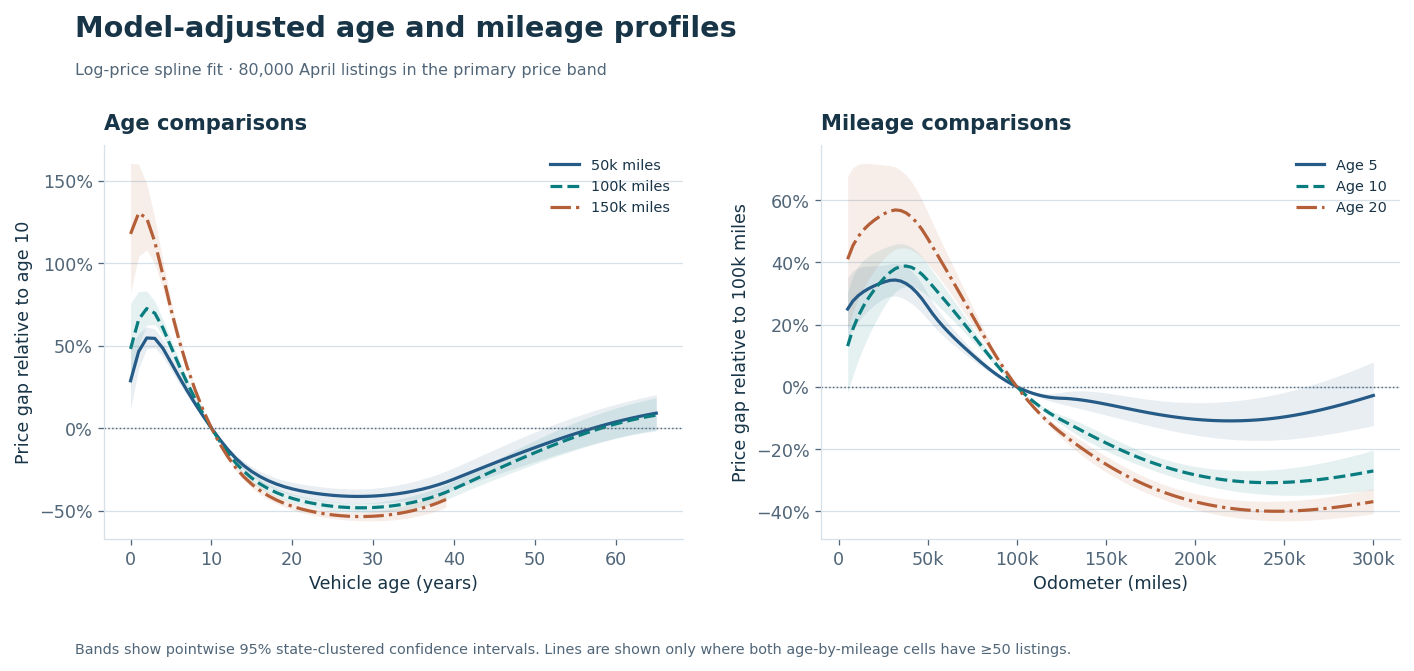

In [6]:
fit = fit_adjusted(april)
assert fit["rank"] == fit["columns"], "Unexpected rank deficiency in the spline design."
anchors = [
    ("Age 20 vs 10, 100k miles", 20, 100_000, 10, 100_000),
    ("Age 45 vs 22, 100k miles", 45, 100_000, 22, 100_000),
    ("150k vs 50k miles, age 10", 10, 150_000, 10, 50_000),
]
effects = []
for label, age, miles, reference_age, reference_miles in anchors:
    support = min(support_counts(april, [age], [miles])[0],
                  support_counts(april, [reference_age], [reference_miles])[0])
    assert support >= MIN_SUPPORT
    estimate, low, high = adjusted_difference(fit, [age], [miles], [reference_age], [reference_miles])[0]
    effects.append({"Contrast": label, "Gap (%)": estimate, "95% low (%)": low, "95% high (%)": high,
                    "Minimum support": support})
effects = pd.DataFrame(effects).set_index("Contrast")
display(effects.style.format({
    "Gap (%)": "{:+.1f}", "95% low (%)": "{:+.1f}", "95% high (%)": "{:+.1f}",
    "Minimum support": "{:,}",
}).set_caption(f"Adjustment fit: {fit['n']:,} April listings · {fit['clusters']} state or DC clusters"))

fig, axes = plt.subplots(1, 2, figsize=(12.8, 6.0))
fig.subplots_adjust(left=.09, right=.97, bottom=.20, top=.77, wspace=.24)
colors = [BLUE, TEAL, ORANGE]
styles = ["-", "--", "-."]
for panel, (title, x, anchors_axis) in enumerate([
    ("Age comparisons", np.arange(0, 66), [50_000, 100_000, 150_000]),
    ("Mileage comparisons", np.linspace(5_000, 300_000, 100), [5, 10, 20]),
]):
    ax = axes[panel]
    for fixed, color, ls in zip(anchors_axis, colors, styles):
        if panel == 0:
            age, miles, ref_age, ref_miles = x, fixed, 10, fixed
            label = f"{fixed//1_000}k miles"
        else:
            age, miles, ref_age, ref_miles = fixed, x, fixed, 100_000
            label = f"Age {fixed}"
        values = adjusted_difference(fit, age, miles, ref_age, ref_miles)
        has_support = ((support_counts(april, age, miles) >= MIN_SUPPORT)
                       & (support_counts(april, ref_age, ref_miles) >= MIN_SUPPORT))
        masked = np.where(has_support[:, None], values, np.nan)
        ax.plot(x, masked[:, 0], ls=ls, color=color, lw=2, label=label)
        ax.fill_between(x, masked[:, 1], masked[:, 2], color=color, alpha=.10, linewidth=0)
    ax.axhline(0, color=MUTED, lw=.9, ls=":")
    ax.grid(axis="y")
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_title(title, loc="left", pad=10)
    ax.legend(loc="upper right", frameon=False, ncols=1, fontsize=9)
axes[0].set_xlabel("Vehicle age (years)")
axes[0].set_ylabel("Price gap relative to age 10")
axes[1].set_xlabel("Odometer (miles)")
axes[1].set_ylabel("Price gap relative to 100k miles")
axes[1].xaxis.set_major_formatter(miles_tick)
figure_notes(fig, "Model-adjusted age and mileage profiles",
             f"Log-price spline fit · {fit['n']:,} April listings in the primary price band",
             "Bands show pointwise 95% state-clustered confidence intervals. Lines are shown only where both age-by-mileage cells have ≥50 listings.")
show_figure(fig, "03_adjusted_profiles")


The vertical axis expresses differences in fitted geometric mean asking price while the other model inputs are held fixed. Uncertainty reflects clustered sampling variation within this specification. The bands do not account for alternative model choices.

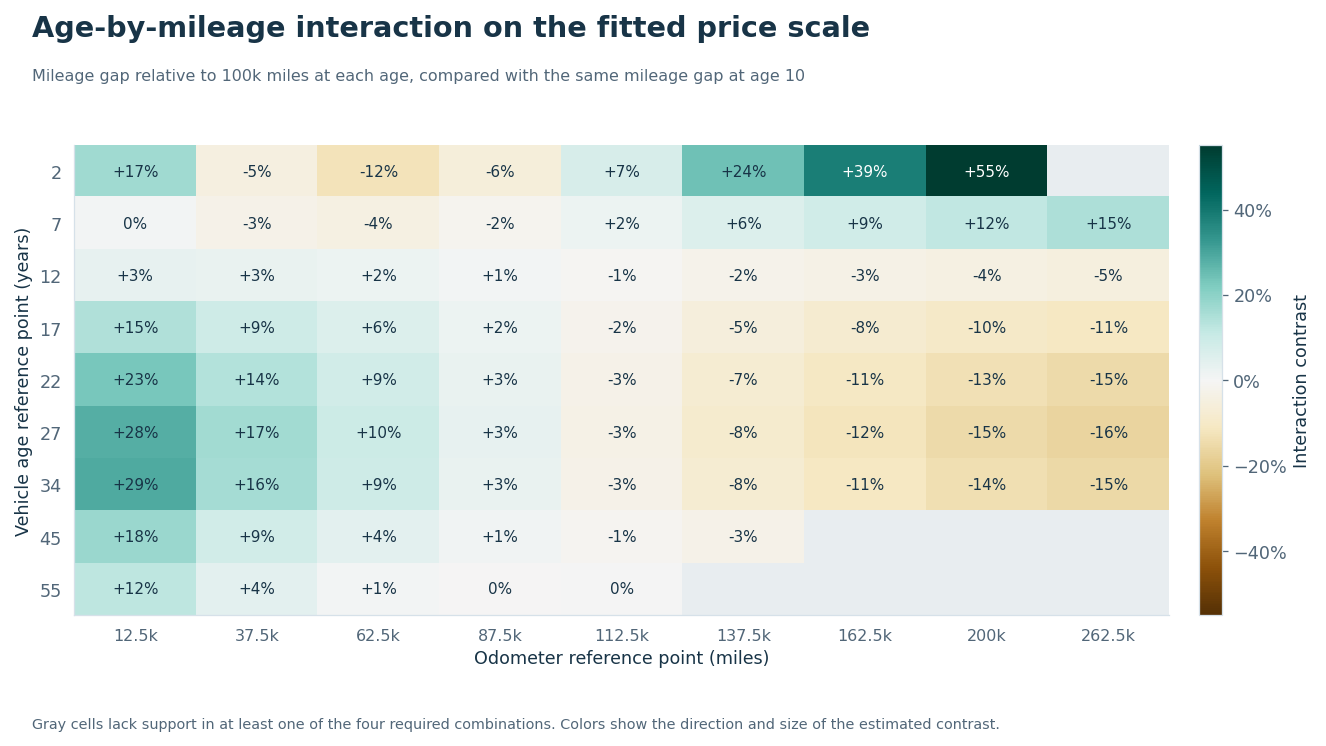

In [7]:
display_ages = np.array([2, 7, 12, 17, 22, 27, 34, 45, 55])
display_miles = np.array([12_500, 37_500, 62_500, 87_500, 112_500, 137_500, 162_500, 200_000, 262_500])
a, m = np.meshgrid(display_ages, display_miles, indexing="ij")
age_points, mile_points = a.ravel(), m.ravel()
common_support = np.minimum.reduce([
    support_counts(april, age_points, mile_points),
    support_counts(april, age_points, 100_000),
    support_counts(april, 10, mile_points),
    np.repeat(support_counts(april, [10], [100_000])[0], len(age_points)),
])
interaction = adjusted_difference(fit, age_points, mile_points, 10, 100_000, interaction=True)[:, 0]
visible = np.where(common_support >= MIN_SUPPORT, interaction, np.nan).reshape(a.shape)
limit = max(10, 5*np.ceil(np.nanmax(np.abs(visible))/5))

fig, ax = plt.subplots(figsize=(12.2, 6.7))
fig.subplots_adjust(left=.10, right=.94, bottom=.18, top=.79)
cmap = plt.get_cmap("BrBG").copy()
cmap.set_bad("#e8edf0")
hm = ax.imshow(visible, cmap=cmap, norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
               aspect="auto", interpolation="nearest")
for (i, j), value in np.ndenumerate(visible):
    if np.isfinite(value):
        ax.text(j, i, f"{value:+.0f}%" if abs(value) >= .5 else "0%", ha="center", va="center", fontsize=9.5,
                color="white" if abs(value) > .58*limit else INK)
ax.set_xticks(np.arange(len(display_miles)), [f"{v/1_000:g}k" for v in display_miles], fontsize=10)
ax.set_yticks(np.arange(len(display_ages)), display_ages)
ax.set_xlabel("Odometer reference point (miles)")
ax.set_ylabel("Vehicle age reference point (years)")
ax.tick_params(length=0, pad=8)
legend = fig.colorbar(hm, ax=ax, fraction=.046, pad=.025, format=PercentFormatter(100))
legend.set_label("Interaction contrast")
figure_notes(fig, "Age-by-mileage interaction on the fitted price scale",
             "Mileage gap relative to 100k miles at each age, compared with the same mileage gap at age 10",
             "Gray cells lack support in at least one of the four required combinations. Colors show the direction and size of the estimated contrast.")
show_figure(fig, "04_age_mileage_interaction")


### 4. Quantile models for the spread of asking prices

A point prediction hides the variation across listings. Gradient boosting at the 25th, 50th and 75th quantiles estimates lower, middle and upper conditional prices. Train on up to 90,000 earlier April listings, selected reproducibly after the same match removal as the spline validation. Score on April 25–30. The baseline at each quantile is the corresponding training price quantile. Independent estimates can cross, so the displayed range sorts predictions within each listing. Pinball loss and the fraction below each estimated quantile are evaluated before sorting.

,Observed below quantile,Model loss (USD),Baseline loss (USD)
quantile,,,
0.250000,26.2%,"$1,700","$3,580"
0.500000,49.6%,"$2,280","$5,528"
0.750000,72.8%,"$2,064","$5,039"


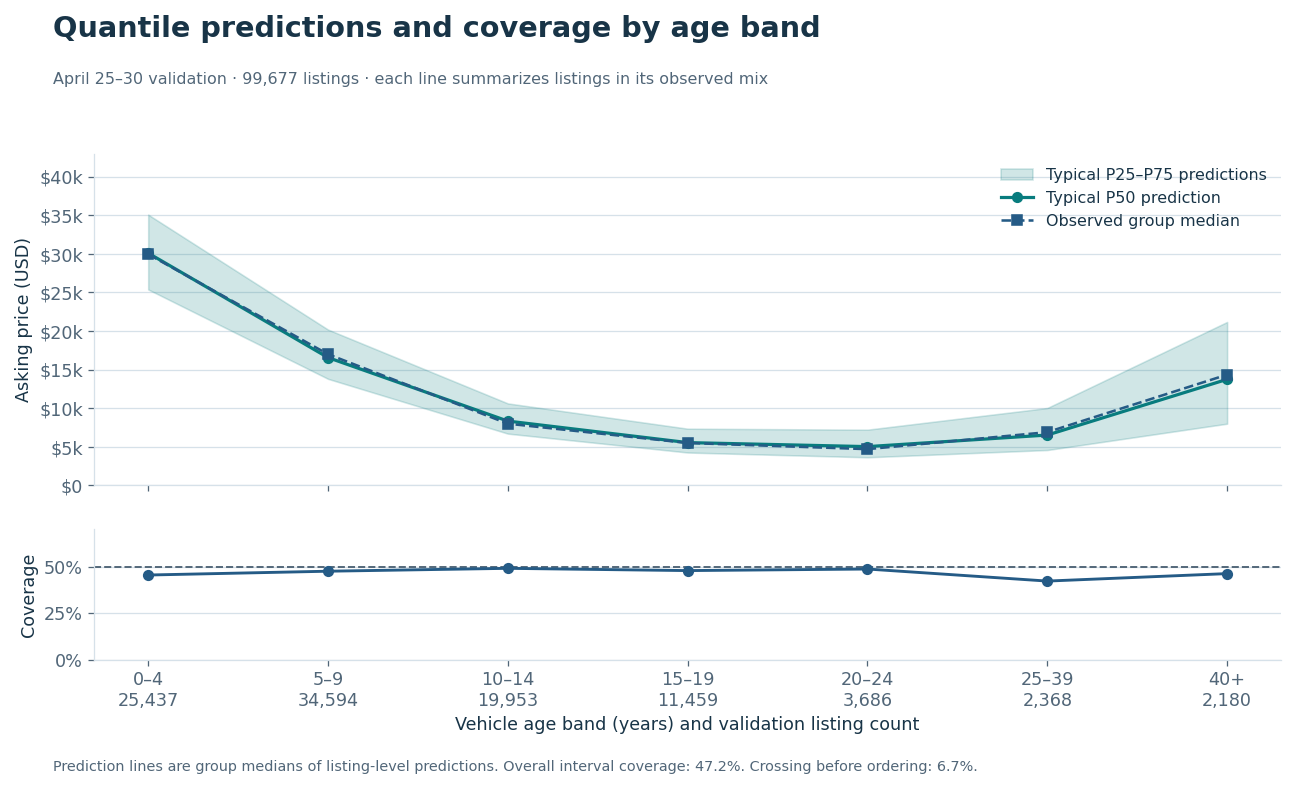

In [8]:
quantile = quantile_diagnostic(*final_april)
display(quantile["scores"].rename(columns={
    "test_fraction_below": "Observed below quantile", "pinball_usd": "Model loss (USD)",
    "baseline_pinball_usd": "Baseline loss (USD)",
}).style.format({
    "Observed below quantile": "{:.1%}", "Model loss (USD)": "${:,.0f}", "Baseline loss (USD)": "${:,.0f}",
}))
by_age = quantile["age"]
x = np.arange(len(by_age))
fig, axes = plt.subplots(2, 1, figsize=(12, 7.1), sharex=True,
                         gridspec_kw={"height_ratios": [2.8, 1.1], "hspace": .19})
fig.subplots_adjust(left=.10, right=.96, bottom=.17, top=.79)
p = axes[0]
p.fill_between(x, by_age.median_p25.to_numpy(), by_age.median_p75.to_numpy(),
               color=TEAL, alpha=.19, label="Typical P25–P75 predictions")
p.plot(x, by_age.median_p50, marker="o", color=TEAL, lw=2, label="Typical P50 prediction")
p.plot(x, by_age.observed_median, marker="s", color=BLUE, lw=1.6, ls="--",
       label="Observed group median")
p.yaxis.set_major_formatter(usd_tick)
p.set_ylabel("Asking price (USD)")
p.set_ylim(0, max(43_000, by_age.median_p75.max()*1.12))
p.grid(axis="y")
p.legend(loc="upper right", frameon=False, fontsize=10)
coverage = axes[1]
coverage.axhline(.5, color=MUTED, lw=1.2, ls="--")
coverage.plot(x, by_age.coverage, marker="o", color=BLUE, lw=1.8)
coverage.set_ylim(0, .70)
coverage.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
coverage.set_ylabel("Coverage")
coverage.set_xticks(x, [f"{label}\n{int(n):,}" for label, n in zip(by_age.index, by_age.n)])
coverage.set_xlabel("Vehicle age band (years) and validation listing count")
coverage.grid(axis="y")
figure_notes(fig, "Quantile predictions and coverage by age band",
             f"April 25–30 validation · {quantile['test_n']:,} listings · each line summarizes listings in its observed mix",
             f"Prediction lines are group medians of listing-level predictions. Overall interval coverage: {quantile['coverage']:.1%}. "
             f"Crossing before ordering: {quantile['crossing_rate']:.1%}.")
show_figure(fig, "05_quantile_predictions")


## Takeaways

- The older-vehicle rebound survives adjustment for recorded make, type and mileage within limited overlap. Show the raw and adjusted estimates together with the retained listing counts.
- Nonlinear age and mileage terms improve prediction across all three April windows. The added interaction improves MAE by about $30 per listing over additive splines, with larger visual differences in some supported combinations.
- Quantile predictions add information about spread and uneven coverage by age band. For a central range intended to cover half of listings, the realized overall coverage is 47.2%.
- The data cover one short period of asking prices and include repeated and self-reported listings. The adjustment and validation results describe this snapshot and its retained comparison cohorts.

In [9]:
summary = {
    "cohort": audit.to_dict(),
    "raw_age": age_stats.reset_index().to_dict(orient="records"),
    "raw_mileage": mile_stats.reset_index().to_dict(orient="records"),
    "rebound": rebound.reset_index().to_dict(orient="records"),
    "validation": validation.to_dict(orient="records"),
    "adjusted": {"n": fit["n"], "clusters": fit["clusters"],
                 "contrasts": effects.reset_index().to_dict(orient="records")},
    "quantile": {"train_n": quantile["train_n"], "test_n": quantile["test_n"],
                 "coverage": quantile["coverage"], "crossing_rate": quantile["crossing_rate"],
                 "scores": quantile["scores"].reset_index().to_dict(orient="records"),
                 "by_age": by_age.reset_index().to_dict(orient="records")},
}
(output_dir / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2),
                                         encoding="utf-8")
print("Saved aggregate Q2 summary and SVGs to outputs/q2/.")


Saved aggregate Q2 summary and SVGs to outputs/q2/.
